# 5.3 How Neural Networks Learn from Text

**Module 5 · Note 3**

In Notes 5.1 and 5.2, our raw data was already made of numbers: every pixel had a brightness between 0 and 255. The challenge was turning those numbers into a *useful* description.

Text starts one step further back. A sentence is a sequence of **symbols** (letters, spaces, punctuation), and a neural network cannot multiply a weight by the letter "g". So before a network can learn anything from text, we must answer a more basic question: *how do we turn words into numbers at all?* And then: *how do we make those numbers meaningful*, so that "great" and "excellent" end up close together and "great" and "terrible" do not?

The answer is the **embedding**: a learned vector of numbers for each word. Embeddings are one of the most important ideas in modern AI. Every language model, every semantic search engine and every chatbot begins by turning text into embeddings. In this note we build them from the ground up, train them two different ways, and discover something important: an embedding learns whatever its training objective rewards.

**Key question:** *How can a network turn words, which are just symbols, into numbers that capture meaning?*

**By the end of this note you will be able to:**
- explain why raw text cannot be fed to a network, and what tokenisation does;
- build a vocabulary and convert text into token IDs;
- explain why one-hot vectors cannot express similarity, and how embedding layers fix this;
- measure similarity between words with cosine similarity;
- train embeddings with two different objectives and explain, with measurements, why they learn different things;
- explain the difference between static and contextual representations.

**Before you start:** read Notes 5.1 and 5.2. You should be comfortable with PyTorch tensors and shapes, `nn.Module`, and the training loop.

### Setup

Run this cell first. Alongside PyTorch, we use **pandas** to load the dataset and Python's built-in `re` (regular expressions) and `collections` modules to process text.

In [1]:
import os, re, collections, urllib.request
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)
np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch", torch.__version__, "| device:", device)

PyTorch 2.14.1+cu130 | device: cpu


## 1. The Big Picture: From Text to Numerical Representations

Here is the whole journey a piece of text takes before a network can learn from it. Every later section explains one step of it.

1. **Raw text:** `"This movie wasn't GOOD.<br />It was great!"`
2. **Tokenisation:** split the text into units called **tokens**, here words: `this`, `movie`, `wasn't`, `good`, `it`, `was`, `great`.
3. **Token IDs:** look each token up in a fixed **vocabulary** (a numbered list of all known tokens) and replace it with its number.
4. **Embeddings:** replace each ID with a learned vector, for example 32 numbers per word. Similar words should get similar vectors.
5. **Model:** combine the vectors and make a prediction, for example "positive review".

> 🖼 *IMAGE 5.3.1 — From Text to Embeddings.* A vertical flow of five labelled rows on a white background, connected by downward arrows. Row 1 "Raw text": a speech-bubble containing `This movie wasn't GOOD.<br />It was great!`. Row 2 "Tokens": seven rounded rectangles in a line: `this` `movie` `wasn't` `good` `it` `was` `great`. Row 3 "Token IDs": the same seven boxes now showing integers `11` `17` `291` `49` `9` `13` `80`, with a small inset table on the right labelled "vocabulary" listing "2 → the", "11 → this", "49 → good", "80 → great". Row 4 "Embeddings": below each ID box, a short vertical column of 6 coloured cells (heat-map colours), labelled "one learned vector per token". Row 5 "Model": the columns feed into a single orange box labelled "network", with an output arrow to a badge "positive". Takeaway: text becomes numbers in two steps, first IDs (arbitrary labels), then embeddings (meaningful vectors).

The first three steps are fixed preprocessing. Step 4 is where the learning happens, and it is the focus of this note.

We will work with **IMDb movie reviews**: 50,000 reviews from the Internet Movie Database, each labelled *positive* or *negative*. It is one of the most widely used datasets for learning about text, and we will return to it in Modules 7 and 8. The download happens only the first time you run the cell.

In [2]:
URL = "https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv"
PATH = "data/imdb/IMDB-Dataset.csv"
os.makedirs("data/imdb", exist_ok=True)
if not os.path.exists(PATH):
    urllib.request.urlretrieve(URL, PATH)
print(f"file size: {os.path.getsize(PATH) / 1e6:.0f} MB")
df = pd.read_csv(PATH)
print("rows:", len(df), "| columns:", list(df.columns))
print("exact duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates().sample(frac=1, random_state=0).reset_index(drop=True)   # remove duplicates, shuffle
print("rows after removing duplicates:", len(df))
print(df.sentiment.value_counts().to_dict())

file size: 66 MB


rows: 50000 | columns: ['review', 'sentiment']
exact duplicate rows: 418


rows after removing duplicates: 49582
{'positive': 24884, 'negative': 24698}


The file has 50,000 rows with two columns, `review` and `sentiment`. But 418 rows are **exact duplicates**: the same review text with the same label, appearing more than once. Duplicates are dangerous: if one copy lands in the training set and another in the validation set, the model is tested on a review it has already seen, and its score looks better than it really is. So we remove them, leaving 49,582 reviews (24,884 positive and 24,698 negative, almost perfectly balanced), and shuffle the order.

> **Common mistake:** splitting a dataset into training and validation sets *before* removing duplicates. Copies of the same example then end up on both sides of the split, and validation accuracy is inflated. Deduplicate first, then split. You will meet this issue again, in more depth, in Module 8.

To keep this notebook fast, we use 20,000 reviews for training and 5,000 for validation. Here is the start of the first training review:

In [3]:
train_df, val_df = df.iloc[:20000], df.iloc[20000:25000]
print("train:", len(train_df), "| validation:", len(val_df))
review = train_df.review.iloc[0]
print(review[:400])

train: 20000 | validation: 5000
Originally I was a Tenacious D fan of their first album and naturally listened to a few tracks off The P.O.D. and was rather disappointed. After watching the movie, my view was changed. The movie is pretty funny from beginning to the end and found my self engaged in it even though it was really was a stupid storyline because of the attitudes that KG and Jaybles portray in the movie. <br /><br />Mu


## 2. Why Neural Networks Cannot Process Raw Text Directly

Look closely at that review and think about it from a network's point of view. Three problems stand out.

**Problem 1: text is made of symbols, not numbers.** A network can only do arithmetic. Every character does have a numeric code (its *Unicode code point*), but those codes are arbitrary labels.

In [4]:
words_per_review = train_df.review.str.split().str.len()
print("words per review: min", words_per_review.min(), "| median", int(words_per_review.median()),
      "| max", words_per_review.max())
print("first 12 characters as code points:", [ord(c) for c in review[:12]])

words per review: min 10 | median 173 | max 2470
first 12 characters as code points: [79, 114, 105, 103, 105, 110, 97, 108, 108, 121, 32, 73]


The capital `O` that begins the review is stored as 79 and the `r` after it as 114. Nothing about 79 or 114 relates to meaning. By that numbering, "good" and "food" differ by one letter and would look almost identical, while "good" and "great" would look quite different. Arithmetic on character codes is arithmetic on spelling, not meaning.

**Problem 2: texts have different lengths.** The shortest training review has 10 words, the median has 173 and the longest has 2,470. But the networks you have built expect inputs of a fixed shape, such as a batch of shape `(64, 784)`. Text needs a way to be cut and padded to a common shape.

**Problem 3: the same meaning can be written in many ways.** "GOOD", "Good" and "good." are the same word to a reader but different strings to a computer. The review also contains HTML line-break tags, `<br />`, left over from the web page it was copied from.

The rest of this note solves these problems one at a time: tokenisation deals with Problem 3 and prepares for Problem 1; token IDs and embeddings solve Problem 1; padding and truncation solve Problem 2.

> **Check yourself 1.** Why would it be a poor idea to represent each word by the sum of its characters' code points?

## 3. Tokenisation and Token IDs

### 3.1 Splitting text into tokens

**Tokenisation** means splitting text into the units the model will treat as its basic building blocks: the **tokens**. The simplest idea, splitting on spaces, already runs into trouble:

In [5]:
def tokenize(text):
    text = text.lower().replace("<br />", " ")
    return re.findall(r"[a-z']+", text)

sentence = "This movie wasn't GOOD.<br /><br />It was great!"
print("split on spaces:", sentence.split())
print("our tokenizer:  ", tokenize(sentence))

split on spaces: ['This', 'movie', "wasn't", 'GOOD.<br', '/><br', '/>It', 'was', 'great!']
our tokenizer:   ['this', 'movie', "wasn't", 'good', 'it', 'was', 'great']


Splitting on spaces produces tokens such as `'GOOD.<br'` and `'/>It'`, which mix words with punctuation and HTML. Our small `tokenize` function does three things instead: it lowercases the text, removes the `<br />` tags, and keeps only runs of letters and apostrophes. The result, `['this', 'movie', "wasn't", 'good', 'it', 'was', 'great']`, is much cleaner.

Every tokeniser involves choices like these, and they matter. Lowercasing means "Apple" (the company) and "apple" (the fruit) become the same token. Dropping punctuation throws away the difference between "great!" and "great?". There is no perfect tokeniser, only one that suits the task. In this note we use whole words. In Module 6 you will meet **subword** tokenisers, which split rare words into common pieces, and which every modern language model uses.

### 3.2 Building a vocabulary

Next we tokenise all 20,000 training reviews and count how often each word appears.

In [6]:
train_tokens = [tokenize(t) for t in train_df.review]
val_tokens = [tokenize(t) for t in val_df.review]
counts = collections.Counter(w for doc in train_tokens for w in doc)
total = sum(counts.values())
print("tokens in training reviews:", total)
print("distinct words:", len(counts))
for n in [1000, 10000]:
    covered = sum(c for _, c in counts.most_common(n)) / total
    print(f"the {n} most common words cover {covered:.1%} of all tokens")
print("10 most common:", [w for w, _ in counts.most_common(10)])

tokens in training reviews: 4617067
distinct words: 79754
the 1000 most common words cover 76.3% of all tokens


the 10000 most common words cover 94.3% of all tokens
10 most common: ['the', 'and', 'a', 'of', 'to', 'is', 'in', 'it', 'i', 'this']


The training reviews contain 4,617,067 tokens but only 79,754 distinct words. The counts are extremely uneven: the 1,000 most common words cover 76.3% of all the tokens, and the 10,000 most common cover 94.3%. The most common words are tiny "function words" such as *the*, *and*, *a* and *of*.

The plot below shows this unevenness. Each point is one word, ranked from most common to least common, plotted against how often it occurs. Both axes are logarithmic (each step is a factor of 10).

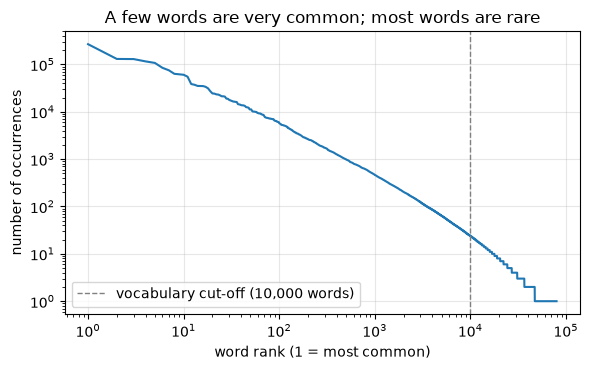

occurrences of the 10,000th most common word: 24
words that occur exactly once: 32674


In [7]:
freqs = np.array(sorted(counts.values(), reverse=True))
plt.figure(figsize=(6, 3.8))
plt.loglog(np.arange(1, len(freqs) + 1), freqs)
plt.axvline(10000, color="grey", ls="--", lw=1, label="vocabulary cut-off (10,000 words)")
plt.xlabel("word rank (1 = most common)"); plt.ylabel("number of occurrences")
plt.title("A few words are very common; most words are rare"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("occurrences of the 10,000th most common word:", freqs[9999])
print("words that occur exactly once:", (freqs == 1).sum())

The curve falls steadily: a handful of words occur hundreds of thousands of times, while the 10,000th most common word occurs only 24 times, and 32,674 words, about 40% of all distinct words, occur exactly once. This pattern, where a word's frequency falls roughly in proportion to its rank, is called **Zipf's law**, and it holds for almost every language and every large body of text.

It also tells us how to build a sensible **vocabulary**. Words that appear only once or twice are too rare for a model to learn anything reliable about. So we keep the 10,000 most common words and add two special tokens:

- **`<pad>`** (ID 0): a filler token used to make short texts as long as long ones (Section 9.1).
- **`<unk>`** (ID 1): "unknown", used for every word that is not in the vocabulary.

We then build two lookup tables: `itos` ("integer to string") maps an ID to its word, and `stoi` ("string to integer") maps a word to its ID.

In [8]:
VOCAB_SIZE = 10000
itos = ["<pad>", "<unk>"] + [w for w, _ in counts.most_common(VOCAB_SIZE)]   # id -> word
stoi = {w: i for i, w in enumerate(itos)}                                    # word -> id
PAD, UNK = 0, 1
def encode(tokens):
    return [stoi.get(w, UNK) for w in tokens]

print("vocabulary size including <pad> and <unk>:", len(itos))
print(tokenize(sentence))
print(encode(tokenize(sentence)))
print("id 2 is", repr(itos[2]), "| id", stoi["great"], "is 'great'")
unk_rate = np.mean([i == UNK for doc in val_tokens for i in encode(doc)])
print(f"share of validation tokens that become <unk>: {unk_rate:.1%}")

vocabulary size including <pad> and <unk>: 10002
['this', 'movie', "wasn't", 'good', 'it', 'was', 'great']
[11, 17, 291, 49, 9, 13, 80]
id 2 is 'the' | id 80 is 'great'
share of validation tokens that become <unk>: 6.0%


Our example sentence has become the list of numbers `[11, 17, 291, 49, 9, 13, 80]`. Common words get small IDs because we numbered the vocabulary by frequency: `the` is ID 2 (right after the two special tokens), and `great` is ID 80.

On the validation reviews, 6.0% of tokens are not in the vocabulary and become `<unk>`. That is the price of a fixed vocabulary: the model will see `<unk>` in place of rare names, misspellings and unusual words.

> **Key terms**
> - **Token:** one unit of text the model works with; here, a word.
> - **Tokenisation:** splitting text into tokens.
> - **Vocabulary:** the fixed list of tokens the model knows, each with a number.
> - **Token ID:** the number of a token in the vocabulary.
> - **`<unk>` / `<pad>`:** special tokens for unknown words and for padding.

Token IDs solve the "symbols are not numbers" problem, but only on the surface. **An ID is just a label**, like a seat number. Word 80 is not "bigger" than word 49 in any meaningful way, and words 49 and 50 are not similar just because their numbers are close. Feeding the raw IDs into a network as if they were measurements would make it treat these arbitrary labels as quantities. We need a better way to give the network each word.

> **Check yourself 2.** Our vocabulary covers 94.3% of training tokens. Why is the share of `<unk>` tokens on the validation reviews (6.0%) slightly higher than the 5.7% you might expect from that figure?

## 4. One-Hot Encoding and Its Limitations

The classic way to give a network a categorical value without implying any order is **one-hot encoding**, which you have probably used for categorical columns in classical machine learning. Each word becomes a vector as long as the vocabulary, filled with zeros except for a single 1 at the word's ID.

In [9]:
def one_hot(word):
    v = torch.zeros(len(itos))
    v[stoi[word]] = 1.0
    return v

good, great, terrible = one_hot("good"), one_hot("great"), one_hot("terrible")
print("one-hot length:", good.shape[0], "| non-zero entries:", int(good.sum()))
print("good . great    =", (good @ great).item())
print("good . terrible =", (good @ terrible).item())
doc_len = 200
print(f"a {doc_len}-token review as one-hot vectors: {doc_len} x {len(itos)} = {doc_len * len(itos):,} numbers")

one-hot length: 10002 | non-zero entries: 1
good . great    = 0.0
good . terrible = 0.0
a 200-token review as one-hot vectors: 200 x 10002 = 2,000,400 numbers


Each one-hot vector has 10,002 entries, and exactly 1 of them is non-zero. One-hot vectors solve the ordering problem, since no word is "bigger" than another. But they create two new problems.

**They are huge and wasteful.** A single 200-token review becomes 200 × 10,002 = 2,000,400 numbers, almost all zeros.

**They make every word equally different from every other word.** A standard way to measure how similar two vectors are is their **dot product**: multiply matching entries and add them up. For one-hot vectors, the 1s are always in different places, so the dot product between any two different words is 0. As the output shows, "good" is exactly as similar to "great" (0.0) as it is to "terrible" (0.0). One-hot vectors carry no notion of meaning at all, so a model cannot transfer anything it learns about "great" to "excellent".

What we would like is a *short* vector for each word, made of ordinary numbers rather than mostly zeros, arranged so that similar words have similar vectors. That is exactly what an embedding is.

> **Check yourself 3.** If we doubled the vocabulary to 20,000 words, what would happen to the length of each one-hot vector, and to the similarity between "good" and "great"?

## 5. Word Embeddings and Embedding Layers

An **embedding layer** is, at heart, a **lookup table**: a matrix with one row per word in the vocabulary. Row 49 holds the vector for "good", row 80 holds the vector for "great", and so on. To embed a token, you simply fetch its row. In PyTorch this is `nn.Embedding(num_embeddings, embedding_dim)`, where `num_embeddings` is the vocabulary size and `embedding_dim` is the length of each vector.

The crucial point is that the table's entries are **ordinary learnable parameters**. They start random and are adjusted by backpropagation, like any other weights, so that the vectors become useful for the task.

In [10]:
torch.manual_seed(0)
emb = nn.Embedding(num_embeddings=len(itos), embedding_dim=8)
print("embedding table:", tuple(emb.weight.shape), "| parameters:", emb.weight.numel())
ids = torch.tensor([stoi["good"], stoi["great"]])
looked_up = emb(ids)
via_one_hot = torch.stack([good, great]) @ emb.weight
print("lookup:\n", looked_up.detach())
print("same as one-hot @ table?", torch.allclose(looked_up, via_one_hot))

embedding table: (10002, 8) | parameters: 80016
lookup:
 

tensor([[ 1.4502,  4.1015,  1.1182, -1.5668, -0.6990,  0.5744,  1.2381, -0.6405],
        [ 0.5408, -0.9478,  0.2021, -0.3507,  0.5450,  1.5412,  0.6002, -0.3380]])
same as one-hot @ table? True


Our table has shape `(10002, 8)`: one row of 8 numbers for each of the 10,002 tokens, which makes 80,016 parameters. Looking up "good" and "great" returns their two rows. The numbers are random, because nothing has been trained yet.

The last line of the output reveals what an embedding layer really is. Multiplying a one-hot vector by the table picks out exactly one row, so **an embedding lookup gives the same result as one-hot encoding followed by a linear layer**, and PyTorch confirms the two are identical (`True`). The embedding layer just skips the wasteful multiplication by thousands of zeros and fetches the row directly.

> 🖼 *IMAGE 5.3.2 — An Embedding Is a Lookup Table.* On the left, a tall narrow table drawn as a grid with 8 columns and many rows (only some drawn, with "⋮" between groups), with row labels on its left edge: "0 <pad>", "1 <unk>", "2 the", "⋮", "49 good", "⋮", "80 great", "⋮", "10001 …". The rows for "good" and "great" are highlighted in orange and blue. On the right, a token-ID box "49" with an arrow pointing into the table at row 49, and a second arrow coming out to the right holding the 8-number orange row, labelled "vector for 'good'". Beneath the table, a caption box: "Same result as one-hot × table, without multiplying by 10,001 zeros". Along the top, a bracket over the table's columns labelled "embedding_dim = 8", and along the left a bracket labelled "num_embeddings = 10,002". Takeaway: an embedding layer stores one learnable vector per token and simply looks it up.

Embedding layers work on whole batches of token IDs at once. A batch of shape `(B, T)` (B texts, each T tokens long) becomes a tensor of shape `(B, T, D)`, adding one dimension of size D for the vector.

In [11]:
batch_ids = torch.tensor([encode(tokenize("the plot was great")),
                          encode(tokenize("the acting was awful"))])
print("token ids:", tuple(batch_ids.shape), "->", "embeddings:", tuple(emb(batch_ids).shape))
for d in [8, 64, 300]:
    print(f"embedding_dim={d:>3}: {len(itos) * d:>9,} parameters")

token ids: (2, 4) -> embeddings: (2, 4, 8)
embedding_dim=  8:    80,016 parameters
embedding_dim= 64:   640,128 parameters
embedding_dim=300: 3,000,600 parameters


Two sentences of 4 tokens each, shape `(2, 4)`, become `(2, 4, 8)`: each of the 8 tokens has been replaced by its 8-number vector.

> **Common mistake:** passing token IDs with a floating-point `dtype` to an embedding layer. Embedding layers need *integer* IDs (`torch.long`), because an ID is a row number, not a quantity.

> **Key terms**
> - **Embedding:** a learned vector of numbers that represents a token.
> - **Embedding layer:** a learnable lookup table with one vector per vocabulary entry (`nn.Embedding`).
> - **Embedding dimension:** the length of each vector (`embedding_dim`).

## 6. Embedding Dimensions and Vector Representations

How long should each word's vector be? The output above shows the parameter cost for our 10,002-word vocabulary: 80,016 parameters with 8 dimensions, 640,128 with 64, and 3,000,600 with 300.

It helps to think of each dimension as one "axis of meaning" that the model can use to tell words apart. With only 2 dimensions you could perhaps separate positive words from negative words, and formal words from casual ones, and nothing else. More dimensions allow more distinctions: tone, topic, grammar, whether a word is about people or objects, and so on. But nobody tells the network what each axis should mean. The axes are learned, and usually no single dimension corresponds neatly to a human concept; the meaning is spread across all of them together.

The trade-off is familiar from Module 3:

- **Too few dimensions:** the vectors cannot hold enough distinctions, and the model underfits.
- **Too many dimensions:** many more parameters to learn, which needs more data and invites overfitting, especially for rare words.

Word embeddings trained on their own typically use somewhere between tens and a few hundred dimensions; the embeddings inside large language models are much longer. In this note we use 32 dimensions for the sentiment model and 50 for the second model in Section 9.

> **Check yourself 4.** A vocabulary has 50,000 tokens and an embedding dimension of 512. How many parameters does the embedding table have?

## 7. Semantic Similarity and Cosine Similarity

If embeddings are supposed to place similar words close together, we need a way to measure "close". For word vectors, the standard measure is **cosine similarity**.

Imagine each vector as an arrow pointing out from the origin. Cosine similarity looks only at the **angle** between two arrows, not at their length:

$$\cos(a, b) = \frac{a \cdot b}{\|a\|\,\|b\|}$$

Here a · b is the dot product from Section 4, and ‖a‖ is the **length** (or **norm**) of vector a, the square root of the sum of its squared entries. Dividing by both lengths removes the effect of size, so only direction counts. The result always lies between −1 and +1:

- **+1:** the arrows point in exactly the same direction.
- **0:** they are at a right angle; the vectors are unrelated.
- **−1:** they point in exactly opposite directions.

Let's check this on small 2D vectors whose angles we can picture:

In [12]:
def cosine(a, b):
    return (a @ b / (a.norm() * b.norm())).item()

pairs = {"same direction": ([1., 1.], [2., 2.]), "right angle": ([1., 0.], [0., 1.]),
         "45 degrees": ([1., 0.], [1., 1.]), "opposite": ([1., 1.], [-1., -1.])}
for name, (a, b) in pairs.items():
    print(f"{name:<15} {a} vs {b}: cosine = {cosine(torch.tensor(a), torch.tensor(b)):.3f}")

same direction  [1.0, 1.0] vs [2.0, 2.0]: cosine = 1.000
right angle     [1.0, 0.0] vs [0.0, 1.0]: cosine = 0.000
45 degrees      [1.0, 0.0] vs [1.0, 1.0]: cosine = 0.707
opposite        [1.0, 1.0] vs [-1.0, -1.0]: cosine = -1.000


`[1, 1]` and `[2, 2]` point the same way (one is just longer), so their cosine is 1.000, even though they are not equal. `[1, 0]` and `[0, 1]` are at a right angle: 0.000. `[1, 0]` and `[1, 1]` are 45° apart: 0.707. And `[1, 1]` and `[−1, −1]` point in opposite directions: −1.000.

> 🖼 *IMAGE 5.3.3 — Cosine Similarity Is About Angle.* Four small square panels in a row on a white background, each showing x and y axes and two arrows from the origin. Panel 1 "same direction, cos = 1.000": a short blue arrow [1,1] lying along a longer orange arrow [2,2]. Panel 2 "45°, cos = 0.707": blue [1,0] along the x-axis and orange [1,1] at 45°, with the angle marked. Panel 3 "right angle, cos = 0.000": blue [1,0] and orange [0,1], with a small square marking the right angle. Panel 4 "opposite, cos = −1.000": blue [1,1] and orange [−1,−1] pointing away from each other. Beneath all panels: "Length doesn't matter; only the angle does." Takeaway: cosine similarity measures whether two vectors point the same way.

Now apply cosine similarity to the untrained embedding table from Section 5:

In [13]:
def vec(table, w):
    return table[stoi[w]]
W0 = emb.weight.detach()
for a, b in [("good", "great"), ("good", "terrible"), ("good", "the")]:
    print(f"untrained: cos({a}, {b}) = {cosine(vec(W0, a), vec(W0, b)):+.3f}")

untrained: cos(good, great) = -0.081
untrained: cos(good, terrible) = -0.682
untrained: cos(good, the) = -0.714


These numbers mean nothing. "Good" comes out *more* similar to "great" (−0.081) than to "terrible" (−0.682) or "the" (−0.714), but that is pure luck: the table is random. With only 8 dimensions, random vectors can easily have large positive or negative cosines by chance. An embedding table becomes meaningful only after it has been **trained**, and, as Section 9 will show, *what* it becomes depends entirely on what it was trained to do.

> **Key terms**
> - **Dot product:** multiply matching entries of two vectors and add the results.
> - **Norm (length):** the size of a vector, the square root of the sum of its squared entries.
> - **Cosine similarity:** the dot product divided by both norms; it measures the angle between two vectors, from −1 to +1.

> **Check yourself 5.** Two word vectors have a cosine similarity of 0.98, but one is three times as long as the other. Are they similar, according to cosine similarity?

## 8. Static vs. Contextual Representations

Before we train anything, there is one limitation of embedding layers that is important to understand, because it explains why the field moved on to the Transformers of Module 6.

Consider the word "bank" in these two sentences:

- *She sat by the bank of the river.*
- *He deposited cash at the bank.*

To a reader, these are two different meanings. But an embedding layer is a lookup table, and "bank" has only one row. So it must receive exactly the same vector in both sentences:

In [14]:
s1 = tokenize("she sat by the bank of the river")
s2 = tokenize("he deposited cash at the bank")
v1 = emb(torch.tensor(encode(s1)))[s1.index("bank")]
v2 = emb(torch.tensor(encode(s2)))[s2.index("bank")]
print("'bank' in sentence 1 vs sentence 2: cosine =", round(cosine(v1.detach(), v2.detach()), 3))

'bank' in sentence 1 vs sentence 2: cosine = 1.0


The cosine similarity is 1.0: the two vectors are identical. This is called a **static** representation: each word gets one fixed vector, whatever its surroundings. Static embeddings cannot tell the two meanings of "bank" apart, cannot see that "not" reverses "good", and cannot tell "dog bites man" from "man bites dog" if the vectors are simply averaged.

A **contextual** representation, by contrast, gives each word a vector that depends on the words around it. "Bank" near "river" and "bank" near "cash" would get different vectors. Producing contextual representations requires a model that lets words exchange information with one another. Sequence models (Note 5.4) and, above all, Transformers (Module 6) do exactly this. They still begin with an embedding layer like ours, and then transform those static vectors into contextual ones.

> 🖼 *IMAGE 5.3.4 — Static vs. Contextual.* Two side-by-side panels on a white background. Left panel titled "Static embedding": the two sentences "sat by the river bank" and "cash at the bank" each written on a line, with the word "bank" in both connected by arrows to one single shared vector (a column of 6 grey cells) in the middle, labelled "one vector for every use of 'bank'". Right panel titled "Contextual representation": the same two sentences, but now each "bank" has its own vector: the first a column of blue-green cells with a small river icon, the second a column of gold cells with a coin icon, and thin arrows from "river" and "cash" bending into their respective vectors, labelled "vector depends on the neighbours". Takeaway: static embeddings give a word one meaning; contextual models give it a meaning per sentence.

> **Key terms**
> - **Static representation:** one fixed vector per word, the same in every context.
> - **Contextual representation:** a vector for a word that depends on the surrounding words.

> **Check yourself 6.** A sentiment model averages static word embeddings to represent a review. Why might it struggle with the review "not good at all"?

## 9. Text Embeddings in Practice with PyTorch

Now we train embeddings for real, in two different ways, and compare what they learn.

### 9.1 Turning reviews into a fixed-size tensor

Reviews have different lengths, but a batch must be a rectangular tensor. The standard solution has two parts:

- **Truncation:** cut every review to at most `MAX_LEN` tokens; we use 200.
- **Padding:** fill shorter reviews up to 200 with the `<pad>` token (ID 0).

In [15]:
MAX_LEN = 200
def to_tensor(token_lists):
    X = torch.full((len(token_lists), MAX_LEN), PAD, dtype=torch.long)
    for i, toks in enumerate(token_lists):
        ids = encode(toks)[:MAX_LEN]                  # truncate long reviews
        X[i, :len(ids)] = torch.tensor(ids, dtype=torch.long)     # shorter reviews stay padded
    return X

X_train, X_val = to_tensor(train_tokens), to_tensor(val_tokens)
y_train = torch.tensor((train_df.sentiment == "positive").values, dtype=torch.float32)
y_val = torch.tensor((val_df.sentiment == "positive").values, dtype=torch.float32)
print("X_train:", tuple(X_train.shape), "| X_val:", tuple(X_val.shape))
print(f"share of training reviews longer than {MAX_LEN} tokens (truncated): {np.mean([len(t) > MAX_LEN for t in train_tokens]):.1%}")
print(f"share of positions that are padding: {(X_train == PAD).float().mean().item():.1%}")

X_train: (20000, 200) | X_val: (5000, 200)
share of training reviews longer than 200 tokens (truncated): 40.4%
share of positions that are padding: 20.9%


The training set is now a tensor of shape `(20000, 200)`: 20,000 reviews, each exactly 200 token IDs. Truncation affects 40.4% of training reviews, which are longer than 200 tokens, and 20.9% of all positions in the tensor are padding.

Truncating that many reviews loses information, because the end of a review often contains its verdict. It is a deliberate trade-off between accuracy and speed. Padding, meanwhile, must not influence the prediction: a review should not become more negative just because it is short. We deal with that next.

### 9.2 Objective 1: learning embeddings for sentiment

Our first model is deliberately simple. It is a **bag of embeddings**: look up the vector for every token, average the vectors of the real (non-padding) tokens, and feed that one average vector to a linear layer that outputs a single score. A positive score means "positive review". The loss is `BCEWithLogitsLoss`, the binary cross-entropy loss for two-class problems.

The line that handles padding is the `mask`: it is 1 for real tokens and 0 for padding, so that padding vectors are multiplied by zero and excluded from the average. We also pass `padding_idx=PAD` to the embedding layer, which keeps the `<pad>` vector fixed at zero and never trains it.

The embedding table is trained *only* through the sentiment loss. The words' vectors are free to become whatever helps tell positive reviews from negative ones. We train for 4 epochs and keep the epoch with the best validation accuracy.

In [16]:
class BagOfEmbeddings(nn.Module):
    def __init__(self, vocab_size, dim=32):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, dim, padding_idx=PAD)
        self.out = nn.Linear(dim, 1)
    def forward(self, x):                          # x: (B, T) token ids
        e = self.emb(x)                            # (B, T, D)
        mask = (x != PAD).unsqueeze(-1).float()    # (B, T, 1): 1 for real tokens, 0 for padding
        mean = (e * mask).sum(1) / mask.sum(1).clamp(min=1)   # (B, D): average of real tokens
        return self.out(mean).squeeze(-1)          # (B,): one score per review

torch.manual_seed(0)
clf = BagOfEmbeddings(len(itos))
opt = torch.optim.Adam(clf.parameters(), lr=5e-3)
loss_fn = nn.BCEWithLogitsLoss()
snaps, val_accs = [], []
for epoch in range(4):
    perm = torch.randperm(len(X_train)); total_loss, n = 0.0, 0
    for i in range(0, len(X_train), 64):
        b = perm[i:i+64]
        opt.zero_grad(); loss = loss_fn(clf(X_train[b]), y_train[b]); loss.backward(); opt.step()
        total_loss += loss.item(); n += 1
    with torch.no_grad():
        acc = ((clf(X_val) > 0).float() == y_val).float().mean().item()
    val_accs.append(acc); snaps.append({k: v.clone() for k, v in clf.state_dict().items()})
    print(f"epoch {epoch+1}: train loss {total_loss/n:.3f} | val acc {acc:.4f}")
best = int(np.argmax(val_accs)); _ = clf.load_state_dict(snaps[best])
print("best epoch on validation:", best + 1)

epoch 1: train loss 0.536 | val acc 0.8272


epoch 2: train loss 0.314 | val acc 0.8578


epoch 3: train loss 0.247 | val acc 0.8646


epoch 4: train loss 0.208 | val acc 0.8632
best epoch on validation: 3


Validation accuracy rises to 0.8646 at epoch 3, then slips to 0.8632 at epoch 4 while the training loss keeps falling. That is the first sign of overfitting, so we keep the epoch 3 weights. Not bad for a model that ignores word order completely.

Now the interesting part: what did the embedding table learn? For a few words, we find the **nearest neighbours**: the vocabulary words whose vectors have the highest cosine similarity to that word's vector.

In [17]:
def neighbours(table, word, k=5):
    T = F.normalize(table, dim=1)
    sims = T @ T[stoi[word]]
    top = sims.topk(k + 1).indices[1:]               # skip the word itself
    return [(itos[i], round(sims[i].item(), 2)) for i in top]

W_sent = clf.emb.weight.detach()
for w in ["excellent", "awful", "boring", "husband", "music", "actor"]:
    print(f"{w:<10}", neighbours(W_sent, w))

excellent  [('wonderfully', 0.88), ('best', 0.85), ('fantastic', 0.85), ('snippets', 0.85), ('hilarious', 0.84)]
awful      [('poorly', 0.88), ('dull', 0.88), ('waste', 0.88), ('wooden', 0.87), ('worst', 0.86)]
boring     [('worst', 0.88), ('waste', 0.88), ('amateurish', 0.87), ('worse', 0.86), ('script', 0.85)]
husband    [('betray', 0.61), ('aimed', 0.61), ('crude', 0.57), ('shrek', 0.56), ('mean', 0.55)]
music      [('testament', 0.63), ('ida', 0.62), ('evokes', 0.62), ('uncertain', 0.57), ('aussie', 0.56)]
actor      [('characterization', 0.79), ('diane', 0.72), ('superficial', 0.68), ('exercise', 0.67), ('kissing', 0.66)]


The sentiment words have very sensible neighbours. "Excellent" sits next to *wonderfully*, *best* and *fantastic*; "awful" sits next to *poorly*, *dull*, *waste* and *worst*. But look at the neutral words. "Husband" is next to *betray*, *aimed* and *crude*; "music" is next to *testament*, *ida* and *evokes*; "actor" is next to *characterization* and *diane*. These are essentially random, and their similarities (around 0.55 to 0.79) are noticeably lower than those of the sentiment words (around 0.85).

This makes perfect sense once you remember what the table was trained for. The sentiment loss only ever asked one question: *does this word push a review towards positive or negative?* So the embeddings organised themselves along that single question. Words with no sentiment, like "husband" and "music", were never pushed into any meaningful arrangement.

### 9.3 Objective 2: learning embeddings from context (skip-gram)

Can we learn embeddings that capture *general* meaning instead? A famous idea from linguistics says yes: **"You shall know a word by the company it keeps."** Words that appear in similar contexts tend to have similar meanings. "Husband" and "wife" both appear near "married", "her", "his" and "divorce"; "music" and "soundtrack" both appear near "score", "songs" and "beautiful".

**Skip-gram** turns this idea into a training objective. It needs no labels at all, only raw text:

1. Take a word in the text, the **centre** word.
2. Look at the words up to a few positions on either side, the **context** words. Each (centre, context) pair is a positive example: "these two words appeared together".
3. Also pick a few random words from the vocabulary, called **negative samples** or "noise" words. Each (centre, random word) pair is a negative example: "these probably did *not* appear together".
4. Train two embedding tables so that the dot product of a centre word's vector with a true context word's vector is high, and with a noise word's vector is low.

This is the training method behind **word2vec**, one of the most influential models in natural-language processing. Because it learns from text alone, it is an example of **self-supervised learning**: the training labels ("did these words appear together?") come from the data itself.

First we build the training pairs. We also randomly drop many occurrences of very frequent words such as "the", a step called **subsampling**, because pairs like ("the", "movie") appear constantly and teach very little.

In [18]:
SG_DOCS = 15000
rng = np.random.default_rng(0)
ids = np.array([i for doc in train_tokens[:SG_DOCS] for i in encode(doc) if i > UNK])
freq = np.bincount(ids, minlength=len(itos)) / len(ids)
keep = rng.random(len(ids)) < np.minimum(1.0, np.sqrt(1e-4 / np.maximum(freq[ids], 1e-12)))
ids = ids[keep]          # randomly drop very frequent words such as "the" (subsampling)
WINDOW = 5
centre, context = [], []
for k in range(1, WINDOW + 1):
    centre += [ids[:-k], ids[k:]]; context += [ids[k:], ids[:-k]]
centre = torch.tensor(np.concatenate(centre)); context = torch.tensor(np.concatenate(context))
print("reviews used:", SG_DOCS, "| window: up to", WINDOW, "words either side")
print("tokens kept after subsampling:", len(ids), "| (centre, context) pairs:", len(centre))

reviews used: 15000 | window: up to 5 words either side
tokens kept after subsampling: 1307513 | (centre, context) pairs: 13075100


From 15,000 training reviews, with a window of up to 5 words on each side, subsampling keeps 1,307,513 tokens, which produce 13,075,100 (centre, context) pairs. Now we train, for one pass over all the pairs.

Inside the loop, `pos` is the dot-product score for each true pair and `neg` holds the scores for the 5 noise words of each pair. The loss uses `logsigmoid`, the logarithm of the sigmoid function, to push `pos` up and `neg` down. It is the same idea as binary cross-entropy, with the true pairs labelled 1 and the noise pairs labelled 0.

In [19]:
torch.manual_seed(0)
noise = torch.tensor(np.maximum(freq, 1e-12) ** 0.75); noise /= noise.sum()
E_in = nn.Embedding(len(itos), 50); E_out = nn.Embedding(len(itos), 50)
nn.init.uniform_(E_in.weight, -0.01, 0.01); nn.init.zeros_(E_out.weight)
opt = torch.optim.Adam(list(E_in.parameters()) + list(E_out.parameters()), lr=3e-3)
perm = torch.randperm(len(centre)); B, NEG = 4096, 5
print("vector size:", E_in.weight.shape[1], "| pairs per step:", B, "| random 'noise' words per pair:", NEG)
losses = []
for step, i in enumerate(range(0, len(centre), B)):
    b = perm[i:i+B]; c, o = centre[b], context[b]
    negs = torch.multinomial(noise, len(b) * NEG, replacement=True).view(len(b), NEG)
    v = E_in(c)                                               # (B, 50) centre-word vectors
    pos = (v * E_out(o)).sum(-1)                              # (B,) score for the true context word
    neg = torch.bmm(E_out(negs), v.unsqueeze(-1)).squeeze(-1) # (B, NEG) scores for random words
    loss = -(F.logsigmoid(pos).mean() + F.logsigmoid(-neg).sum(1).mean())
    opt.zero_grad(); loss.backward(); opt.step()
    losses.append(loss.item())
print("steps:", len(losses), f"| loss first 100 steps {np.mean(losses[:100]):.3f} | last 100 steps {np.mean(losses[-100:]):.3f}")

vector size: 50 | pairs per step: 4096 | random 'noise' words per pair: 5


steps: 3193 | loss first 100 steps 3.420 | last 100 steps 2.599


The loss falls from an average of 3.420 over the first 100 steps to 2.599 over the last 100. Now the same nearest-neighbour test, on the skip-gram embeddings:

In [20]:
W_sg = E_in.weight.detach()
for w in ["excellent", "awful", "boring", "husband", "music", "actor"]:
    print(f"{w:<10}", neighbours(W_sg, w))

excellent  [('superb', 0.94), ('outstanding', 0.91), ('marvellous', 0.91), ('performances', 0.9), ('exceptional', 0.9)]
awful      [('terrible', 0.94), ('atrocious', 0.87), ('bad', 0.86), ('horrible', 0.86), ('lousy', 0.85)]
boring     [('storyline', 0.9), ('unrealistic', 0.88), ('utterly', 0.87), ('uninteresting', 0.87), ('predictable', 0.87)]
husband    [("mother's", 0.92), ('wife', 0.92), ('sister', 0.91), ('mother', 0.91), ('abusive', 0.91)]
music      [('soundtrack', 0.88), ('jazz', 0.85), ('score', 0.85), ('composed', 0.84), ('songs', 0.84)]
actor      [('russell', 0.87), ('role', 0.87), ('comedian', 0.87), ('reeves', 0.86), ('glover', 0.85)]


The neutral words now have meaningful neighbours. "Husband" sits next to *wife*, *sister* and *mother*; "music" next to *soundtrack*, *jazz*, *score* and *songs*; "actor" next to *role* and *comedian* (and the surnames of a few actors). The sentiment words still have sensible neighbours too: "excellent" next to *superb* and *outstanding*, "awful" next to *terrible* and *atrocious*.

### 9.4 Backing the comparison with numbers

Nearest-neighbour lists are easy to cherry-pick, so let's measure the difference more systematically. We take three sets of word pairs:

- **related** pairs, which a reader would call similar in meaning, such as *husband–wife*, *music–soundtrack* and *film–movie*;
- **opposite** pairs with opposite sentiment, such as *excellent–awful* and *love–hate*;
- 200 **random** pairs drawn from the 2,000 most common words, as a baseline.

We compute the average cosine similarity within each set, for three embedding tables: a random untrained one, the sentiment one and the skip-gram one.

In [21]:
related = [("husband", "wife"), ("actor", "actress"), ("music", "soundtrack"), ("film", "movie"),
           ("funny", "hilarious"), ("boring", "dull"), ("director", "directed"), ("book", "novel")]
opposite = [("excellent", "awful"), ("good", "bad"), ("best", "worst"), ("great", "terrible"),
            ("brilliant", "boring"), ("love", "hate")]
rng = np.random.default_rng(1)
random_pairs = [tuple(itos[i] for i in rng.integers(2, 2002, 2)) for _ in range(200)]
rows = []
torch.manual_seed(0)
W_untrained = nn.Embedding(len(itos), 50).weight.detach()      # random 50-dim table for comparison
for name, table in [("untrained", W_untrained), ("sentiment", W_sent), ("skip-gram", W_sg)]:
    m = lambda ps: np.mean([cosine(vec(table, a), vec(table, b)) for a, b in ps])
    rows.append((name, m(related), m(opposite), m(random_pairs)))
print(f"{'embedding':<10} {'related':>8} {'opposite':>9} {'random':>7}")
for r in rows:
    print(f"{r[0]:<10} {r[1]:>8.3f} {r[2]:>9.3f} {r[3]:>7.3f}")

embedding   related  opposite  random
untrained    -0.076     0.085   0.011
sentiment     0.141    -0.609  -0.001
skip-gram     0.815     0.513   0.400


Always read these numbers against the **random** column, which tells you what "no relationship" looks like in each table.

- **Untrained:** all three averages are close to zero (−0.076, 0.085 and 0.011). As expected, random vectors encode nothing.
- **Sentiment:** related pairs average only 0.141, barely above random (−0.001). But opposite pairs are strongly *negative*, at −0.609. This table has learned one thing very well, positive versus negative, and little else.
- **Skip-gram:** related pairs average 0.815, far above its random baseline of 0.400. Notice the baseline itself is high: skip-gram vectors tend to share a common overall direction, which is why comparing against random pairs matters. The surprise is the opposite pairs: 0.513, *above* the random baseline. To skip-gram, "excellent" and "awful" are somewhat **similar**, because they appear in the same kinds of contexts ("the acting was ___", "an ___ film").

Within the 20 words of the picture below, the same story shows up group by group: the family words average −0.06 under the sentiment objective and 0.88 under skip-gram, while the positive words are tightly grouped in both (0.77 and 0.81).

Here is a 2D picture of 20 words from four groups in each table. Each panel is a **PCA** projection (principal component analysis, a method that finds the two directions along which the points vary most and flattens everything onto them). A 2D picture of 32- or 50-dimensional vectors always loses information: these pictures keep 58% and 66% of the variation in the 20 vectors, so treat them as illustrations of the numbers above, not as proof.

sentiment  average cosine within each group: positive 0.77  negative 0.84  family -0.06  music 0.20
skip-gram  average cosine within each group: positive 0.81  negative 0.73  family 0.88  music 0.80
sentiment embedding: the 2D picture keeps 58% of the variation of these 20 vectors
skip-gram embedding: the 2D picture keeps 66% of the variation of these 20 vectors


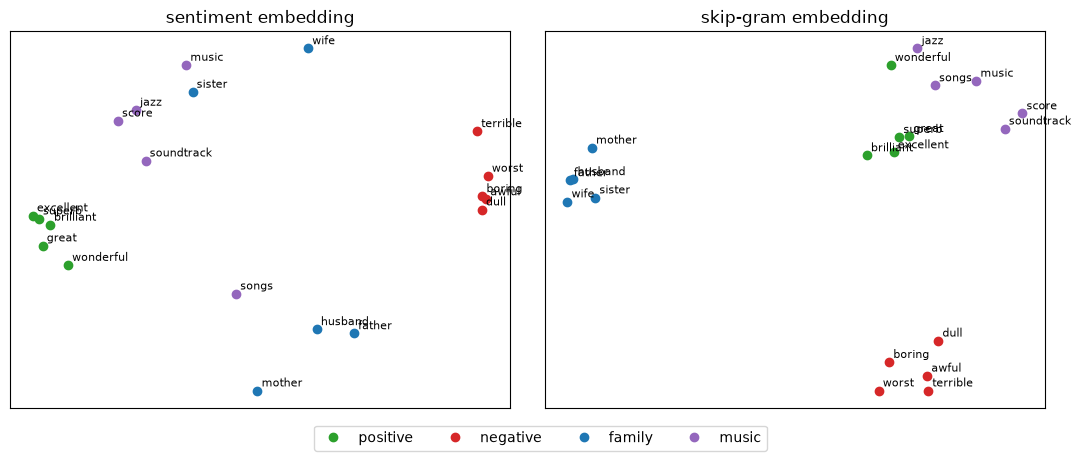

In [22]:
from sklearn.decomposition import PCA
groups = {"positive": ["excellent", "superb", "wonderful", "great", "brilliant"],
          "negative": ["awful", "terrible", "boring", "worst", "dull"],
          "family":   ["husband", "wife", "mother", "father", "sister"],
          "music":    ["music", "soundtrack", "songs", "score", "jazz"]}
colours = {"positive": "tab:green", "negative": "tab:red", "family": "tab:blue", "music": "tab:purple"}
words = [w for g in groups.values() for w in g]
for name, table in [("sentiment", W_sent), ("skip-gram", W_sg)]:
    within = {g: np.mean([cosine(vec(table, a), vec(table, b)) for i, a in enumerate(ws) for b in ws[i+1:]])
              for g, ws in groups.items()}
    print(f"{name:<10} average cosine within each group:", "  ".join(f"{g} {v:.2f}" for g, v in within.items()))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, (name, table) in zip(axes, [("sentiment embedding", W_sent), ("skip-gram embedding", W_sg)]):
    pca = PCA(2).fit(F.normalize(table[[stoi[w] for w in words]], dim=1).numpy())
    pts = pca.transform(F.normalize(table[[stoi[w] for w in words]], dim=1).numpy())
    print(f"{name}: the 2D picture keeps {pca.explained_variance_ratio_.sum():.0%} of the variation of these 20 vectors")
    for (x_, y_), w in zip(pts, words):
        g = next(k for k, v in groups.items() if w in v)
        ax.scatter(x_, y_, color=colours[g]); ax.annotate(w, (x_, y_), fontsize=8, xytext=(3, 3), textcoords="offset points")
    ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=k) for k, c in colours.items()]
fig.legend(handles=handles, loc="lower center", ncol=4); plt.tight_layout(rect=(0, 0.07, 1, 1)); plt.show()

In the sentiment panel, positive and negative words form two tight clusters at opposite sides, while family and music words are scattered without structure. In the skip-gram panel, all four groups form their own clusters.

This is the key lesson of this note: **an embedding learns whatever its training objective rewards.** Same architecture, same vocabulary, same reviews; different objective, different geometry. A sentiment objective builds a "sentiment axis". A context objective builds a map of how words are used, which captures topic and meaning but cannot, by itself, tell good from bad. Neither is "the true meaning" of a word; each is a representation shaped for a purpose. You saw the same idea with images in Note 5.1: a representation is good *for a task*.

### 9.5 The limit of static embeddings

Finally, let's go back to Section 8 and test our sentiment model on four short sentences.

In [23]:
tests = ["the movie was good", "the movie was not good", "the movie was bad", "the movie was not bad"]
with torch.no_grad():
    for t in tests:
        x = torch.tensor([encode(tokenize(t))])
        print(f"{t:<25} P(positive) = {torch.sigmoid(clf(x)).item():.3f}")

the movie was good        P(positive) = 0.982
the movie was not good    P(positive) = 0.569
the movie was bad         P(positive) = 0.000
the movie was not bad     P(positive) = 0.000


"The movie was good" gets a probability of 0.982 of being positive, and "the movie was bad" gets 0.000. So far, so good. But "the movie was not good" still gets 0.569, more likely positive than negative, and "the movie was not bad" gets 0.000, as negative as "bad" itself.

The model cannot understand negation. It sees each word's static vector, averaged together, with no idea that "not" changes the meaning of the word after it. Averaging also throws away word order completely. Fixing this needs a model that processes the words *in relation to one another*, which is exactly where Note 5.4 begins.

> **Common mistake:** judging embeddings by a few hand-picked neighbour lists. As you saw, a sentiment table gives perfect neighbours for "awful" and nonsense for "husband". Always test several kinds of words, and compare against a random baseline.

> **Check yourself 7.** According to the skip-gram embeddings, "excellent" and "awful" are more similar than two random words. Why would using those embeddings, unchanged, for sentiment analysis be risky?

## Putting It All Together

Let's retrace the full path from text to meaning, now that you have built every step.

Raw text is a sequence of **symbols**, of varying length and inconsistent formatting, so a network cannot use it directly. **Tokenisation** splits it into tokens; we used lowercase words. A **vocabulary** of the 10,000 most frequent words covered 94.3% of training tokens, thanks to Zipf's law, with `<unk>` for the rest. **Token IDs** turn tokens into numbers, but those numbers are only labels. **One-hot vectors** remove the false ordering but are enormous, and make every pair of words equally different (dot product 0).

An **embedding layer** replaces each ID with a short, learnable vector. It is equivalent to one-hot encoding followed by a linear layer, but much cheaper. **Cosine similarity** measures how close two embeddings point. But the vectors mean something only after training, and they become whatever the **training objective** rewards:

| Embedding | Related pairs | Opposite-sentiment pairs | Random pairs |
|---|---|---|---|
| Untrained | −0.076 | 0.085 | 0.011 |
| Sentiment objective | 0.141 | −0.609 | −0.001 |
| Skip-gram objective | 0.815 | 0.513 | 0.400 |

Embedding layers are **static**: "bank" gets the same vector in every sentence (cosine 1.0), and a model built only from averaged static vectors cannot handle "not good" (still 0.569 positive). Getting **contextual** representations requires models that combine words with one another, the subject of Note 5.4 and Module 6.

> 🖼 *IMAGE 5.3.5 — One Table, Two Objectives.* A diagram with a single grey grid on the left labelled "embedding table (random at start)". Two arrows branch right. Upper arrow labelled "trained to predict sentiment (labels)" leads to a 2D scatter where green positive words (excellent, superb, great) sit far left, red negative words (awful, worst, dull) sit far right, and blue family words (husband, wife, mother) and purple music words (music, jazz, score) are scattered randomly in between; caption "one strong axis: positive ↔ negative". Lower arrow labelled "trained to predict neighbouring words (no labels)" leads to a scatter with four tidy separate clusters (green, red, blue, purple); caption "clusters by topic and usage". Takeaway: what an embedding learns is decided by its training objective.

## Summary

- Text is a sequence of symbols of varying length; networks need fixed-size numeric tensors.
- **Tokenisation** splits text into tokens; every tokeniser involves choices (case, punctuation, word vs. subword).
- Word frequencies follow **Zipf's law**: 10,000 words covered 94.3% of training tokens, and 32,674 words appeared only once.
- **Token IDs** are labels, not quantities. **One-hot vectors** remove false ordering but are huge and express no similarity.
- An **embedding layer** is a learnable lookup table, equivalent to one-hot × a weight matrix. Shapes go from `(B, T)` to `(B, T, D)`.
- **Cosine similarity** compares vectors by angle, from −1 to +1.
- Embeddings learn what their objective rewards. A sentiment objective learned a positive–negative axis (opposite pairs −0.609) but nothing about topics. Skip-gram learned topic and usage (related pairs 0.815, against a random baseline of 0.400) but puts opposite-sentiment words close together.
- Padding and truncation make text rectangular; masks keep padding out of the computation.
- Embedding layers are **static**; models that average them cannot handle negation or word order. **Contextual** models solve this.

## Glossary

| Term | Meaning |
|---|---|
| Token | One unit of text the model works with (a word, subword or character). |
| Tokenisation | Splitting text into tokens. |
| Vocabulary | The fixed list of tokens a model knows, each with an ID. |
| Token ID | A token's number in the vocabulary; a label, not a quantity. |
| `<unk>` | Special token for words not in the vocabulary. |
| `<pad>` | Special filler token used to make sequences the same length. |
| Zipf's law | The pattern that a word's frequency falls roughly in proportion to its rank. |
| One-hot vector | A vector of zeros with a single 1 marking a category. |
| Embedding | A learned vector representing a token. |
| Embedding layer | A learnable lookup table of embeddings (`nn.Embedding`). |
| Embedding dimension | The length of each embedding vector. |
| Dot product | Sum of products of matching vector entries. |
| Norm | The length of a vector. |
| Cosine similarity | Dot product divided by both norms; measures the angle between vectors. |
| Nearest neighbours | The words whose vectors are most similar to a given word's vector. |
| Bag of embeddings | A model that averages the embeddings of a text's tokens, ignoring order. |
| Mask | A tensor of 1s and 0s marking which positions are real tokens. |
| Truncation / padding | Cutting long sequences / filling short ones to a fixed length. |
| Skip-gram | Learning embeddings by predicting which words appear near each other. |
| Negative sampling | Training against randomly chosen "noise" words that did not appear in the context. |
| Subsampling | Randomly dropping very frequent words from the training text. |
| Self-supervised learning | Learning from labels created automatically from the data itself. |
| Static representation | One fixed vector per word, regardless of context. |
| Contextual representation | A word vector that depends on the surrounding words. |
| PCA | Principal component analysis; projects data onto the directions of greatest variation. |

## Answers to Check Yourself

**1.** The sum of code points depends only on spelling, and different words can share the same sum: "dog" and "god" have identical letters, so identical sums, but very different meanings. And words with similar meanings ("good", "great") would get unrelated sums. The number would carry no information about meaning.

**2.** The vocabulary was chosen using the *training* reviews. Words that are common in training are, by construction, in the vocabulary; the validation reviews contain some words that were rare or absent in training (new names, rare words, typos), so slightly more of their tokens fall outside the vocabulary. This is a small, honest example of the gap between training data and new data.

**3.** Each one-hot vector would grow to about 20,000 entries (plus the special tokens). The similarity between "good" and "great" would still be exactly 0, as for any two different words. More words make one-hot vectors more wasteful, not more meaningful.

**4.** 50,000 × 512 = 25,600,000 parameters.

**5.** Yes. Cosine similarity ignores length and looks only at direction. A cosine of 0.98 means the vectors point in almost the same direction, so they count as very similar, regardless of one being longer.

**6.** The average of the static vectors for "not", "good", "at" and "all" contains the strongly positive vector for "good". Averaging cannot express that "not" reverses the meaning of "good", so the review may be scored as positive. We measured exactly this: "the movie was not good" was still scored 0.569 positive.

**7.** Skip-gram places "excellent" and "awful" relatively close together (average opposite-pair cosine 0.513, above the random baseline of 0.400), because they appear in similar contexts. A sentiment classifier built on these vectors would start from a representation in which positive and negative words are hard to tell apart, so it would need to learn that distinction from labelled data. Embeddings from one objective are not automatically right for a different task.